# 타임아웃 재시도 폴백

**이 노트북에서 할 일**

1. 모델 객체가 답을 기다리는 시간과 다시 시도하는 횟수를 확인하고, 두 값을 직접 적어 요청을 보냅니다.
2. 시간 제한을 아주 짧게 두어 실제 시간 초과 오류를 받고, `with_retry()`로 다시 시도한 횟수를 셉니다.
3. 기본 경로가 시간 초과로 실패하면 `with_fallbacks()`로 다른 모델이 답하게 하고, 응답한 모델 이름을 확인합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스의 모델 `gpt-5.4-mini`와 `gpt-5.4-nano`에 요청을 모두 13번 시도합니다.
답을 받는 요청은 2번이고, 없는 모델 이름으로 보내 오류를 받는 요청이 2번입니다. 나머지 9번은 시간 제한에 걸립니다.

실행 시간은 1분 안팎입니다. 예상 비용은 0.01달러 미만입니다(06절 4절에서 2026-09-17에 확인한 공식 요금 기준).

**강의와 실습 범위** — 강의 시간에는 3~5절, 7절, 9·10절(Before·After)을 설명합니다.
6·8절 값 바꿔 보기는 셀을 함께 실행하고, 결과 읽기는 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
함께 설치되는 openai 패키지는 3.10.0, tenacity는 9.1.4이고, python-dotenv는 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![맨 위 보라 상자 기본 경로 tiny_model gpt-5.4-mini timeout 0.001초가 노란 상자 5절 OpenAITimeoutError is_retryable True로 가고, 왼쪽 갈래는 파란 상자 재시도 with_retry 같은 경로로 모두 3번에서 노란 상자 7절 시도한 횟수 3으로, 오른쪽 갈래는 파란 상자 폴백 with_fallbacks에서 보라 상자 대체 경로 gpt-5.4-nano를 거쳐 노란 상자 10절 AIMessage 응답한 모델 gpt-5.4-nano로 이어지는 흐름도](attachment:05-1-세-가지-장치.png)

위에서 아래로 읽습니다. 맨 위 보라 상자는 기다리는 시간을 0.001초로 둔 기본 경로이고, 노란 상자는 출력으로 확인한 오류와 결과입니다.
시간 초과 오류 아래에서 두 갈래로 나뉩니다. 왼쪽 파란 상자는 같은 경로로 다시 시도하는 재시도, 오른쪽 파란 상자는 다른 모델로 넘기는 폴백입니다.

두 갈래는 7절과 10절에서 따로 실행합니다. 이 노트북은 두 장치를 한 호출에 함께 붙이지 않습니다.
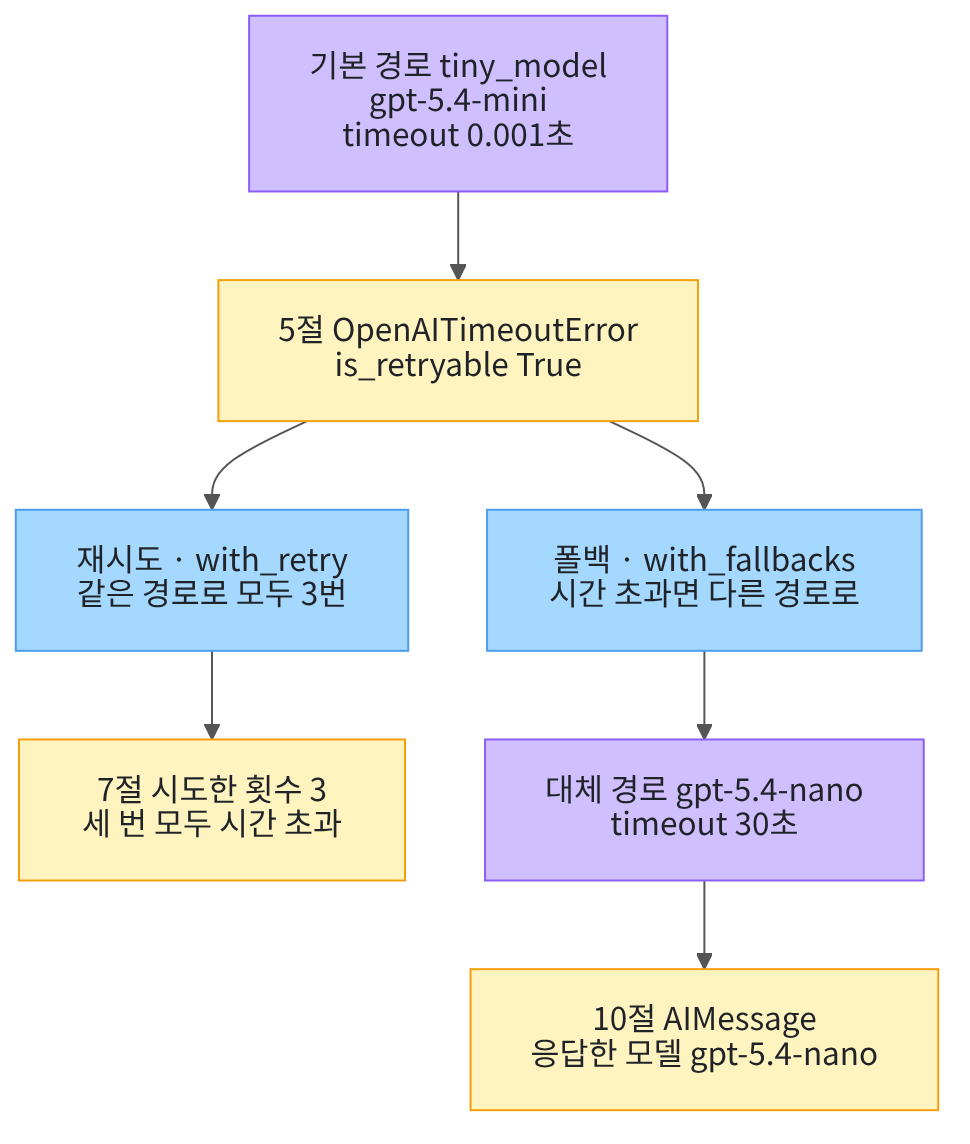

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
패키지 openai는 langchain-openai가 OpenAI 서버에 요청을 보낼 때 쓰는 패키지입니다. 패키지 tenacity는 7절의 `with_retry()`가 다시 시도할 때 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tenacity:", version("tenacity"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
tenacity: 9.1.4
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.10.0`, `tenacity: 9.1.4` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

01절과 같이 모델 객체를 만드는 함수를 불러옵니다. 걸린 시간을 재는 모듈 `time`도 불러옵니다.
이 모듈은 Ch 2 12절에서 `time.perf_counter()`로 걸린 시간을 잴 때 썼습니다.

In [2]:
# 걸린 시간을 재는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import time

from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장과 걸린 시간이 달라질 수 있습니다.
01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 메시지 목록 만들기

이번 절의 질문은 재시도 횟수를 제한하는 이유입니다. system 지시는 02·04절의 「한 문장의 한국어로 답하세요.」를 다시 씁니다.
01절처럼 `(역할, 내용)` 튜플 목록으로 적고, 한 줄씩 출력합니다.

실행 전에 예상합니다. 역할 이름 system과 user가 한 줄씩 나올 것입니다.

In [5]:
# 한 문장으로 답하라는 공통 지시와 이번 질문을 튜플 목록에 담습니다
messages = [
    ("system", "한 문장의 한국어로 답하세요."),
    ("user", "재시도 횟수를 제한해야 하는 이유를 설명하세요."),
]
print("메시지 목록:")
for role, content in messages:
    print(role, "|", content)

메시지 목록:
system | 한 문장의 한국어로 답하세요.
user | 재시도 횟수를 제한해야 하는 이유를 설명하세요.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `system | 한 문장의 한국어로 답하세요.`입니다. 둘째 줄은 `user | 재시도 횟수를 제한해야 하는 이유를 설명하세요.`입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 3. 적지 않은 두 값 보기

01~04절의 모델 객체는 기다리는 시간과 다시 시도하는 횟수를 적지 않았습니다. 적지 않은 두 값이 무엇인지 봅니다.
기다리는 시간의 인자 이름은 `timeout`이지만, 모델 객체에는 속성 `request_timeout`으로 담깁니다. 다시 시도하는 횟수는 속성 `max_retries`입니다.

속성 `root_client`는 모델 객체가 요청을 보낼 때 쓰는 openai 패키지의 클라이언트(요청을 보내는 객체)입니다. 이 객체의 두 값도 함께 출력합니다.
이 절은 기본값이 어디서 오는지 보려고 값을 읽기만 합니다. 이 객체의 설정을 직접 바꾸지 않고, 설정은 `init_chat_model()` 인자로 적습니다.

실행 전에 예상합니다. 적지 않았으니 비어 있다는 뜻의 `None`이 보일 것입니다.

In [6]:
# 01~04절처럼 두 값을 적지 않은 모델 객체의 설정을 봅니다(요청 없음)
print("모델 객체 timeout:", model.request_timeout)
print("모델 객체 max_retries:", model.max_retries)
print("openai 클라이언트 timeout:", model.root_client.timeout)
print("openai 클라이언트 max_retries:", model.root_client.max_retries)

모델 객체 timeout: None
모델 객체 max_retries: None
openai 클라이언트 timeout: None
openai 클라이언트 max_retries: 2


**결과 읽기** — 출력 줄은 `모델 객체 timeout: None`, `모델 객체 max_retries: None`, `openai 클라이언트 timeout: None`, `openai 클라이언트 max_retries: 2`입니다.
모델 객체의 두 값은 비어 있지만, 클라이언트의 다시 시도 횟수는 2였습니다.

설치한 langchain-openai 1.6.0 소스에서, 비어 있는 `max_retries`는 클라이언트에 넘기지 않는 것을 확인했습니다. 그래서 openai 패키지의 기본값 2가 쓰입니다.
기다리는 시간 `None`은 시간 제한을 두지 않는다는 뜻입니다. 서버가 늦으면 답이 올 때까지 기다리게 됩니다. 늦은 서버에 보내는 장면은 이번에 실행하지 않았습니다.

적지 않은 값도 어딘가에서 정해져 있습니다. 4절부터는 두 값을 직접 적습니다.

## 4. 기다리는 시간과 다시 시도하는 횟수 적기

타임아웃(timeout)은 답을 기다리는 최대 시간이고, 단위는 초입니다. 전화 신호음이 오래 가면 끊는 것과 비슷합니다.
재시도(retry)는 실패한 요청을 같은 설정으로 다시 보내는 일입니다. 다시 보내 보는 한 번 한 번을 시도라고 부릅니다.

아래 셀은 `timeout=30`, `max_retries=1`을 준 새 모델 객체를 만듭니다. 01절 노트북 7절처럼 인자를 더해 새 객체를 만듭니다.
실패하면 한 번 더 보내므로, 시도는 최대 2번입니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 두 값이 `None` 대신 적은 값으로 보일 것입니다.

In [7]:
# 기다리는 시간 30초, 다시 시도 1번을 적은 모델 객체를 만듭니다(요청 없음)
limited_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    timeout=30,
    max_retries=1,
)
print("timeout:", limited_model.request_timeout)
print("max_retries:", limited_model.max_retries)

timeout: 30.0
max_retries: 1


**결과 읽기** — 출력 줄은 `timeout: 30.0`과 `max_retries: 1`입니다. 적은 값이 모델 객체에 담겼습니다.

이 모델 객체로 요청을 보냅니다. 01절처럼 답과 끝난 이유, 출력 토큰 수를 출력합니다.
응답 메타데이터의 키 `model_name`도 출력합니다. 서버가 실제로 답한 모델 이름이 담기는 키이고, 10절에서 다시 씁니다.

실행 전에 예상합니다. 30초 안에 답이 와서 끝난 이유는 stop일 것입니다.

In [8]:
# 두 값을 적은 모델 객체로 요청을 보내고, 답과 응답한 모델 이름을 봅니다(시도 1번)
limited_response = limited_model.invoke(messages)
print("답:", limited_response.text)
print("끝난 이유:", limited_response.response_metadata["finish_reason"])
print("출력 토큰 수:", limited_response.usage_metadata["output_tokens"])
print("응답한 모델:", limited_response.response_metadata["model_name"])

답: 재시도 횟수를 제한해야 하는 이유는 무한 반복으로 인한 시스템 자원 낭비와 장애 확산을 막고, 실패를 빠르게 감지해 적절한 복구나 대체 조치를 취할 수 있게 하기 위해서입니다.
끝난 이유: stop
출력 토큰 수: 60
응답한 모델: gpt-5.4-mini-2026-03-17


**결과 읽기** — 출력 줄은 한 문장 답, `끝난 이유: stop`, 출력 토큰 수, `응답한 모델: gpt-5.4-mini-2026-03-17`입니다.
응답한 모델 이름에는 모델 이름 뒤에 날짜가 붙은 판 이름이 담겼습니다.

오류 없이 답을 받았으므로, 이 셀에서 다시 시도가 있었는지는 알 수 없습니다. 기다리는 시간 30초가 쓰였는지도 이 출력에는 보이지 않습니다.
두 설정이 하는 일을 보려면, 실제로 실패하는 요청이 필요합니다.

## 5. 아주 짧은 시간 제한으로 실제 시간 초과 만들기

수업 중에 서버가 늦어지기를 기다릴 수는 없습니다. 대신 기다리는 시간을 0.001초로 아주 짧게 줍니다. 이렇게 하면 답이 오기 전에 실제로 시간 제한에 걸립니다.
다시 시도는 `max_retries=0`으로 끕니다. 그러면 시도는 1번뿐입니다.

실행 전에 예상합니다. 이 셀은 모델 객체만 만들어 오류가 나지 않을 것입니다.

In [9]:
# 기다리는 시간 0.001초, 다시 시도 0번인 모델 객체를 만듭니다(요청 없음)
tiny_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    timeout=0.001,
    max_retries=0,
)
print("timeout:", tiny_model.request_timeout)
print("max_retries:", tiny_model.max_retries)

timeout: 0.001
max_retries: 0


**결과 읽기** — 출력 줄은 `timeout: 0.001`과 `max_retries: 0`입니다. 01절에서 본 것처럼 모델 객체를 만들 때는 요청이 나가지 않아 오류도 없습니다.

이 모델 객체로 요청을 보냅니다. 오류 이름은 02절의 `ModelNotFoundError`처럼 `langchain_core.exceptions`에서 불러옵니다.
시간 초과 오류의 이름은 `ModelTimeoutError`입니다. 요청 앞뒤에서 `time.perf_counter()`를 읽어 걸린 시간도 셉니다. 함수 `round(값, 1)`은 소수 첫째 자리까지 남깁니다.

오류의 속성 `is_retryable`도 출력합니다. 같은 요청을 다시 보내면 성공할 수도 있는 오류인지, LangChain이 오류 종류마다 정해 둔 값입니다.

실행 전에 예상합니다. 시간 초과 오류를 받고, 걸린 시간은 1초보다 훨씬 짧을 것입니다.

In [10]:
# 시간 제한 0.001초 모델로 보내고, 받은 오류와 걸린 시간을 봅니다(시도 1번)
from langchain_core.exceptions import ModelTimeoutError

start_time = time.perf_counter()
try:
    tiny_model.invoke(messages)
except ModelTimeoutError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:", error)
    print("다시 시도할 수 있는 오류인가:", error.is_retryable)
elapsed = time.perf_counter() - start_time
print("걸린 초:", round(elapsed, 1))

오류 종류: OpenAITimeoutError
오류 메시지: Request timed out.
다시 시도할 수 있는 오류인가: True
걸린 초: 0.0


**결과 읽기** — 출력 줄은 `오류 종류: OpenAITimeoutError`, `오류 메시지: Request timed out.`, `다시 시도할 수 있는 오류인가: True`, `걸린 초: 0.0`입니다.
02절의 `OpenAIModelNotFoundError`처럼, OpenAI 통합 패키지의 오류를 LangChain 공통 이름으로 받았습니다.

시간 초과는 다시 보내면 성공할 수도 있는 오류로 정해져 있습니다. 서버가 잠깐 늦었을 수 있기 때문입니다.
이번 오류는 우리가 시간 제한을 너무 짧게 준 탓입니다. 서버가 요청을 받았는지는 이 출력으로 알 수 없습니다.

## 6. 값 바꿔 보기 1 — max_retries 적지 않기

바꾸는 값은 `max_retries` 하나입니다. 5절의 `0`을 적지 않고, 기다리는 시간 0.001초는 그대로 둡니다.
3절에서 본 대로 적지 않으면 openai 클라이언트가 두 번 더 시도합니다. 한 셀에서 모델 객체를 만들고 바로 요청을 보냅니다.

실행 전에 예상합니다. 오류는 같지만, 다시 시도하느라 5절보다 오래 걸릴 것입니다.

In [11]:
# max_retries를 적지 않은 모델로 같은 요청을 보내고, 걸린 시간을 봅니다(시도 3번)
default_retry_model = init_chat_model(
    "openai:gpt-5.4-mini", temperature=0, reasoning_effort="none", timeout=0.001
)
start_time = time.perf_counter()
try:
    default_retry_model.invoke(messages)
except ModelTimeoutError as error:
    print("오류 종류:", type(error).__name__)
elapsed = time.perf_counter() - start_time
print("max_retries:", default_retry_model.max_retries)
print("openai 클라이언트 max_retries:", default_retry_model.root_client.max_retries)
print("걸린 초:", round(elapsed, 1))

오류 종류: OpenAITimeoutError
max_retries: None
openai 클라이언트 max_retries: 2
걸린 초: 1.3


**결과 읽기** — 출력 줄은 `오류 종류: OpenAITimeoutError`, `max_retries: None`, `openai 클라이언트 max_retries: 2`, `걸린 초: 1.3`입니다.
오류는 5절과 같았지만, 걸린 시간은 5절의 0.0초보다 길었습니다.

설치한 openai 3.10.0 소스에서, 시간 초과 뒤 다시 보내기 전에 기다리는 것을 확인했습니다. 첫 기다림은 0.375~0.5초, 둘째는 0.75~1초입니다.
두 번 기다린 시간이 이 셀의 걸린 시간과 맞습니다. 다만 시도 수를 직접 세지는 않았습니다. 7절에서는 시도를 세어 봅니다.

코드 첫 줄 주석의 시도 3번은 소스로 계산한 최대 횟수이고, 이 셀이 센 값은 아닙니다.

## 7. with_retry()로 다시 시도하기

모델 객체 안의 다시 시도는 몇 번 일어났는지 셀 수 없었습니다. 이번에는 LangChain의 메서드 `with_retry()`로 다시 시도하고, 시도를 우리 함수에서 셉니다.
먼저 요청을 보내는 함수를 하나 정의합니다. 함수 `ask_current_model()`은 바깥 이름 `current_model`에 담긴 모델 객체로 요청을 보냅니다.

Ch 5 08절에서 바깥 이름에 후보를 담고 함수를 부른 것과 같은 방법입니다. 부를 때마다 바깥 목록 `attempt_log`에 `"시도"` 한 줄을 적습니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [12]:
# 시도할 때마다 기록 목록에 한 줄을 적고, 바깥 이름 current_model의 모델로 요청을 보내는 함수를 정의합니다
def ask_current_model(input_messages):
    attempt_log.append("시도")
    return current_model.invoke(input_messages)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 바깥 이름 `current_model`과 `attempt_log`는 다음 셀에서 만듭니다.

클래스 `RunnableLambda`는 일반 함수를 `invoke()`로 부를 수 있는 호출 객체로 감쌉니다. 03절의 `RunnableSequence`와 같은 호출 객체입니다. 괄호 안에는 함수 이름만 괄호 없이 넣습니다.
메서드 `with_retry()`의 인자 `retry_if_exception_type`에는 다시 시도할 오류 이름을 튜플로 적습니다. `(ModelTimeoutError,)`처럼 쉼표를 붙여야 원소 하나짜리 튜플이 됩니다.

인자 `stop_after_attempt=3`은 첫 시도를 포함해 모두 3번까지 시도한다는 뜻입니다. 모델은 5절의 `tiny_model`을 씁니다. 이 모델은 `max_retries=0`이라 안에서 다시 시도하지 않습니다.
그래서 함수가 적은 시도 수가 요청을 보내 본 횟수와 같습니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 호출 객체의 종류 이름에 Retry라는 말이 들어 있을 것입니다.

In [13]:
# 함수를 호출 객체로 감싸고, 시간 초과 오류일 때만 모두 3번까지 시도하게 합니다(요청 없음)
from langchain_core.runnables import RunnableLambda

current_model = tiny_model
attempt_log = []
retry_runnable = RunnableLambda(ask_current_model).with_retry(
    retry_if_exception_type=(ModelTimeoutError,),
    stop_after_attempt=3,
)
print("호출 객체 종류:", type(retry_runnable).__name__)

호출 객체 종류: RunnableRetry


**결과 읽기** — 출력 줄은 `호출 객체 종류: RunnableRetry`입니다. 03절에서 양식을 붙인 줄처럼, 이 줄도 호출 객체만 만들고 요청은 보내지 않았습니다.

이 호출 객체로 요청을 보냅니다. 세 번 모두 실패하면 마지막 오류가 나므로, 5절처럼 오류 이름으로 받습니다.
시도 기록과 시도 수, 걸린 시간을 출력하고 시도 수를 `assert`로 확인합니다.

실행 전에 예상합니다. 세 번 모두 시간 제한에 걸려, 시도 기록에 세 줄이 남을 것입니다.

In [14]:
# 다시 시도하는 호출 객체로 보내고, 시도 기록과 걸린 시간을 봅니다(시도 3번)
start_time = time.perf_counter()
try:
    retry_runnable.invoke(messages)
except ModelTimeoutError as error:
    print("오류 종류:", type(error).__name__)
elapsed = time.perf_counter() - start_time
print("시도 기록:", attempt_log)
print("시도한 횟수:", len(attempt_log))
print("걸린 초:", round(elapsed, 1))
assert len(attempt_log) == 3

오류 종류: OpenAITimeoutError
시도 기록: ['시도', '시도', '시도']
시도한 횟수: 3
걸린 초: 4.5


**결과 읽기** — 출력 줄은 `오류 종류: OpenAITimeoutError`, `시도 기록: ['시도', '시도', '시도']`, `시도한 횟수: 3`, `걸린 초: 4.5`입니다. `assert`도 통과했습니다.
함수가 세 번 불렸고, 세 번째 시도의 오류가 셀까지 왔습니다.

걸린 시간이 6절보다 길었습니다. 설치한 langchain-core 1.6.2 소스에서, 다시 시도하기 전에 기다리는 것을 확인했습니다. 첫 기다림은 1~2초, 둘째는 2~3초입니다.
세 번 모두 같은 시간 제한이라 결과도 같았습니다. 실패한 원인이 그대로이면 다시 시도해도 성공하지 않습니다.

## 8. 값 바꿔 보기 2 — 다시 시도하지 않는 오류

바꾸는 값은 바깥 이름 `current_model` 하나입니다. 02절의 없는 모델 이름 `gpt-5.4-mimi`로 만든 모델 객체를 담습니다.
호출 객체 `retry_runnable`은 7절 그대로이고, 시도 기록 목록만 빈 목록으로 다시 만듭니다. 모델 없음 오류 `ModelNotFoundError`는 02절에서 받은 이름입니다.

실행 전에 예상합니다. 이 오류는 다시 시도할 오류 목록에 없으므로, 시도는 1번일 것입니다.

In [15]:
# 02절의 없는 모델 이름으로 바꾸고, 같은 호출 객체로 보냅니다(시도 1번)
from langchain_core.exceptions import ModelNotFoundError

typo_model = init_chat_model("openai:gpt-5.4-mimi", temperature=0, reasoning_effort="none")
current_model = typo_model
attempt_log = []
try:
    retry_runnable.invoke(messages)
except ModelNotFoundError as error:
    print("오류 종류:", type(error).__name__)
    print("다시 시도할 수 있는 오류인가:", error.is_retryable)
print("시도한 횟수:", len(attempt_log))
assert len(attempt_log) == 1

오류 종류: OpenAIModelNotFoundError
다시 시도할 수 있는 오류인가: False
시도한 횟수: 1


**결과 읽기** — 출력 줄은 `오류 종류: OpenAIModelNotFoundError`, `다시 시도할 수 있는 오류인가: False`, `시도한 횟수: 1`입니다. `assert`도 통과했습니다.
목록에 적지 않은 오류라서 `with_retry()`가 다시 시도하지 않았습니다.

없는 모델 이름은 몇 번을 다시 보내도 서버가 같은 404를 보냅니다. LangChain도 이 오류를 다시 시도할 수 없는 오류로 정해 두었습니다.
이런 오류는 다시 시도로 가리지 않고, 코드의 모델 이름을 고칩니다.

## 9. Before — 폴백 없이 기본 경로만 쓰기

이제 사용자에게 답을 보여 줘야 하는 상황이라고 생각합니다. 기본 경로는 5절의 `tiny_model`입니다. 서버가 제시간에 답하지 못한 상황을 이 모델로 대신합니다.
받은 답을 담을 변수 `before_answer`를 `None`으로 두고, 요청이 성공할 때만 답 글을 담습니다.

실행 전에 예상합니다. 시간 초과 오류를 받고, 받은 답은 `None`일 것입니다.

In [16]:
# 폴백 없이 시간 제한 0.001초 모델에만 보내고, 받은 답을 봅니다(시도 1번)
before_answer = None
try:
    before_response = tiny_model.invoke(messages)
    before_answer = before_response.text
except ModelTimeoutError as error:
    print("오류 종류:", type(error).__name__)
print("받은 답:", before_answer)

오류 종류: OpenAITimeoutError
받은 답: None


**결과 읽기** — 출력 줄은 `오류 종류: OpenAITimeoutError`와 `받은 답: None`입니다.
이 셀은 오류를 받아 끝까지 실행했지만, 사용자에게 보여 줄 답이 없습니다. 구문 `try`가 없었다면 이 셀은 오류로 멈췄을 것입니다.

## 10. After — 시간 초과일 때만 다른 모델로 넘기기

폴백(fallback)은 기본 경로가 실패하면 미리 정해 둔 다른 경로로 넘기는 일입니다. 전화가 안 되면 문자를 보내는 것과 비슷합니다.
메서드 `with_fallbacks()`는 대체 경로 목록을 받습니다. 인자 `exceptions_to_handle`에는 7절처럼 넘길 오류 이름을 튜플로 적습니다.

대체 경로는 02절에서 쓴 모델 `gpt-5.4-nano`입니다. 이 모델에는 4절처럼 `timeout=30`, `max_retries=1`을 적습니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 호출 객체의 종류 이름에 Fallbacks라는 말이 들어 있을 것입니다.

In [17]:
# 대체 모델을 만들고, 시간 초과일 때만 그 모델로 넘기는 호출 객체를 만듭니다(요청 없음)
fallback_model = init_chat_model(
    "openai:gpt-5.4-nano",
    temperature=0,
    reasoning_effort="none",
    timeout=30,
    max_retries=1,
)
safe_model = tiny_model.with_fallbacks(
    [fallback_model],
    exceptions_to_handle=(ModelTimeoutError,),
)
print("호출 객체 종류:", type(safe_model).__name__)

호출 객체 종류: RunnableWithFallbacks


**결과 읽기** — 출력 줄은 `호출 객체 종류: RunnableWithFallbacks`입니다. 기본 경로 `tiny_model`에 대체 경로 하나를 붙인 호출 객체입니다.

이 호출 객체로 9절과 같은 메시지 목록을 보냅니다. 답과 함께 기본 경로 모델 이름과, 4절의 키 `model_name`으로 응답한 모델 이름을 출력합니다.
응답한 모델 이름에 nano가 들어 있는지 `assert`로 확인합니다. 답 문장은 확인하지 않습니다.

실행 전에 예상합니다. 답은 받지만, 응답한 모델은 기본 경로의 mini가 아닐 것입니다.

In [18]:
# 폴백을 붙인 호출 객체로 보내고, 답과 응답한 모델 이름을 봅니다(시도 2번)
after_response = safe_model.invoke(messages)
answered_model = after_response.response_metadata["model_name"]
print("응답 객체 종류:", type(after_response).__name__)
print("답:", after_response.text)
print("출력 토큰 수:", after_response.usage_metadata["output_tokens"])
print("기본 경로 모델:", tiny_model.model_name)
print("응답한 모델:", answered_model)
assert "nano" in answered_model

응답 객체 종류: AIMessage
답: 재시도 횟수를 제한해야 하는 이유는 무한 반복으로 인해 시스템 자원과 네트워크 부하가 과도하게 증가하고, 장애가 장기화될 때 전체 서비스 품질을 악화시키기 때문입니다.
출력 토큰 수: 54
기본 경로 모델: gpt-5.4-mini
응답한 모델: gpt-5.4-nano-2026-03-17


**결과 읽기** — 출력 줄은 `응답 객체 종류: AIMessage`, 한 문장 답, 출력 토큰 수, `기본 경로 모델: gpt-5.4-mini`, `응답한 모델: gpt-5.4-nano-2026-03-17`입니다.
오류 없이 답을 받았고, `assert`도 통과했습니다.

답은 받았지만 기본 경로가 성공한 것은 아닙니다. 기본 경로는 시간 제한에 걸렸고, 대체 경로가 답했습니다.
그래서 답과 함께 응답한 모델 이름을 기록합니다. 기본 모델 이름으로 기록하면 사용량과 답의 품질을 다른 모델의 것으로 셉니다.

폴백도 목록에 적은 오류일 때만 넘기는지 확인합니다. 기본 경로를 8절의 `typo_model`로 바꾸고, 같은 대체 경로와 같은 오류 목록을 붙입니다.

실행 전에 예상합니다. 모델 없음 오류는 목록에 없으므로, 대체 모델이 답하지 않고 받은 답은 `None`일 것입니다.

In [19]:
# 기본 경로를 없는 모델 이름으로 바꿔 같은 폴백을 붙이고 보냅니다(시도 1번)
typo_safe_model = typo_model.with_fallbacks(
    [fallback_model],
    exceptions_to_handle=(ModelTimeoutError,),
)
typo_answer = None
try:
    typo_response = typo_safe_model.invoke(messages)
    typo_answer = typo_response.text
except ModelNotFoundError as error:
    print("오류 종류:", type(error).__name__)
print("받은 답:", typo_answer)
assert typo_answer is None

오류 종류: OpenAIModelNotFoundError
받은 답: None


**결과 읽기** — 출력 줄은 `오류 종류: OpenAIModelNotFoundError`와 `받은 답: None`입니다. `assert`도 통과했습니다.
대체 모델로 넘어가지 않고, 모델 없음 오류가 그대로 셀까지 왔습니다.

설치한 langchain-core 1.6.2 소스로 보면, 목록을 넓게 잡을 때는 오타도 대체 모델의 답에 가려집니다. 이 경우는 이번에 실행하지 않았습니다. 넘길 오류를 좁혀 두면, 고쳐야 할 오류는 드러납니다.

## 정리

- 두 값을 적지 않은 모델 객체는 시간 제한이 없었고, openai 클라이언트의 다시 시도 횟수는 2였습니다.
- 메서드 `with_retry()`는 목록에 적은 시간 초과 오류만 모두 3번 시도했고, 모델 없음 오류는 1번으로 멈췄습니다.
- 메서드 `with_fallbacks()`는 시간 초과일 때만 `gpt-5.4-nano`로 넘겼으므로, 응답한 모델 이름을 함께 기록합니다.

다음 06절에서는 같은 과제를 보내고 토큰 수, 비용, 걸린 시간을 한 기록에 모아 비교합니다.